In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
df = pd.read_excel(
    "TCGA-CDR-SupplementalTableS1 (3).xlsx",
    sheet_name="TCGA-CDR"
)

In [5]:
df.shape

(11160, 34)

In [6]:
df["type"].value_counts()

type
BRCA    1097
GBM      596
OV       587
UCEC     548
KIRC     537
HNSC     528
LUAD     522
LGG      515
THCA     507
LUSC     504
PRAD     500
SKCM     470
COAD     459
STAD     443
BLCA     412
LIHC     377
CESC     307
KIRP     291
SARC     261
LAML     200
ESCA     185
PAAD     185
PCPG     179
READ     170
TGCT     134
THYM     124
KICH     113
ACC       92
MESO      87
UVM       80
UCS       57
DLBC      48
CHOL      45
Name: count, dtype: int64

In [7]:
glioma = df[df["type"].isin(["LGG", "GBM"])].copy()

glioma.shape

(1111, 34)

In [8]:
glioma.duplicated().sum()

np.int64(0)

In [9]:
glioma.columns.tolist()

['Unnamed: 0',
 'bcr_patient_barcode',
 'type',
 'age_at_initial_pathologic_diagnosis',
 'gender',
 'race',
 'ajcc_pathologic_tumor_stage',
 'clinical_stage',
 'histological_type',
 'histological_grade',
 'initial_pathologic_dx_year',
 'menopause_status',
 'birth_days_to',
 'vital_status',
 'tumor_status',
 'last_contact_days_to',
 'death_days_to',
 'cause_of_death',
 'new_tumor_event_type',
 'new_tumor_event_site',
 'new_tumor_event_site_other',
 'new_tumor_event_dx_days_to',
 'treatment_outcome_first_course',
 'margin_status',
 'residual_tumor',
 'OS',
 'OS.time',
 'DSS',
 'DSS.time',
 'DFI',
 'DFI.time',
 'PFI',
 'PFI.time',
 'Redaction']

In [10]:
glioma.duplicated().sum()

np.int64(0)

In [11]:
eda = glioma[[
    "bcr_patient_barcode",
    "type",
    "age_at_initial_pathologic_diagnosis",
    "gender",
    "race",
    "histological_type",
    "histological_grade",
    "vital_status",
    "tumor_status",
    "OS",
    "OS.time"
]].copy()

eda.head()

,bcr_patient_barcode,type,age_at_initial_pathologic_diagnosis,gender,race,histological_type,histological_grade,vital_status,tumor_status,OS,OS.time
2645,TCGA-02-0001,GBM,44.0,FEMALE,WHITE,Untreated primary (de novo) GBM,[Not Available],Dead,WITH TUMOR,1.0,358.0
2646,TCGA-02-0003,GBM,50.0,MALE,WHITE,Untreated primary (de novo) GBM,[Not Available],Dead,WITH TUMOR,1.0,144.0
2647,TCGA-02-0004,GBM,59.0,MALE,WHITE,Untreated primary (de novo) GBM,[Not Available],Dead,WITH TUMOR,1.0,345.0
2648,TCGA-02-0006,GBM,56.0,FEMALE,WHITE,Untreated primary (de novo) GBM,[Not Available],Dead,WITH TUMOR,1.0,558.0
2649,TCGA-02-0007,GBM,40.0,FEMALE,WHITE,Treated primary GBM,[Not Available],Dead,WITH TUMOR,1.0,705.0


In [12]:
eda.isna().sum()

bcr_patient_barcode                     0
type                                    0
age_at_initial_pathologic_diagnosis     0
gender                                  0
race                                    0
histological_type                       0
histological_grade                      0
vital_status                            2
tumor_status                           84
OS                                      0
OS.time                                 1
dtype: int64

In [13]:
for column in eda.columns:
    print(f"\n{column}:")
    print(eda[column].value_counts(dropna=False).head(15))


bcr_patient_barcode:
bcr_patient_barcode
TCGA-02-0001    1
TCGA-02-0003    1
TCGA-02-0004    1
TCGA-02-0006    1
TCGA-02-0007    1
TCGA-02-0009    1
TCGA-02-0010    1
TCGA-02-0011    1
TCGA-02-0014    1
TCGA-02-0015    1
TCGA-02-0016    1
TCGA-02-0021    1
TCGA-02-0023    1
TCGA-02-0024    1
TCGA-02-0025    1
Name: count, dtype: int64

type:
type
GBM    596
LGG    515
Name: count, dtype: int64

age_at_initial_pathologic_diagnosis:
age_at_initial_pathologic_diagnosis
54.0    30
52.0    30
59.0    29
63.0    28
58.0    28
57.0    27
51.0    27
61.0    26
38.0    26
60.0    26
48.0    26
47.0    24
53.0    24
36.0    24
40.0    23
Name: count, dtype: int64

gender:
gender
MALE      651
FEMALE    460
Name: count, dtype: int64

race:
race
WHITE                               982
BLACK OR AFRICAN AMERICAN            72
[Not Available]                      27
ASIAN                                21
[Unknown]                             5
[Not Evaluated]                       3
AMERICAN INDIAN

In [14]:
missing_labels = [
    "[Not Available]",
    "[Unknown]",
    "[Not Evaluated]",
    "[Discrepancy]"
]

eda = eda.replace(missing_labels, np.nan)

In [15]:
eda.isna().sum()

bcr_patient_barcode                      0
type                                     0
age_at_initial_pathologic_diagnosis      0
gender                                   0
race                                    35
histological_type                        0
histological_grade                     597
vital_status                             2
tumor_status                            89
OS                                       0
OS.time                                  1
dtype: int64

In [16]:
eda[eda["OS.time"].isna()]

,bcr_patient_barcode,type,age_at_initial_pathologic_diagnosis,gender,race,histological_type,histological_grade,vital_status,tumor_status,OS,OS.time
4915,TCGA-CS-5390,LGG,47.0,FEMALE,WHITE,Oligodendroglioma,G2,Alive,TUMOR FREE,0.0,NaN


In [17]:
eda["OS_months"] = eda["OS.time"] / 30.44

In [18]:
eda[eda["OS.time"].isna()]

,bcr_patient_barcode,type,age_at_initial_pathologic_diagnosis,gender,race,histological_type,histological_grade,vital_status,tumor_status,OS,OS.time,OS_months
4915,TCGA-CS-5390,LGG,47.0,FEMALE,WHITE,Oligodendroglioma,G2,Alive,TUMOR FREE,0.0,NaN,NaN


In [19]:
eda[[
    "age_at_initial_pathologic_diagnosis",
    "OS.time",
    "OS_months"
]].describe()

,age_at_initial_pathologic_diagnosis,OS.time,OS_months
count,1111.000000,1110.000000,1110.000000
mean,50.927993,713.156757,23.428277
std,15.780483,795.758391,26.141866
min,10.000000,0.000000,0.000000
25%,38.000000,228.250000,7.498357
50%,52.000000,479.000000,15.735874
75%,63.000000,867.000000,28.482260
max,89.000000,6423.000000,211.005256


In [20]:
eda.groupby("type")[[
    "age_at_initial_pathologic_diagnosis",
    "OS.time",
    "OS_months"
]].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

age_at_initial_pathologic_diagnosis                                   \
                                   count   mean median    std   min   max   
type                                                                        
GBM                                  596  57.83   59.0  14.41  10.0  89.0   
LGG                                  515  42.94   41.0  13.36  14.0  87.0   

     OS.time                                    OS_months                \
       count    mean median    std  min     max     count   mean median   
type                                                                      
GBM      596  498.08  366.0  537.5  0.0  3881.0       596  16.36  12.02   
LGG      514  962.55  674.0  958.0  0.0  6423.0       514  31.62  22.14   

                          
        std  min     max  
type                      
GBM   17.66  0.0  127.50  
LGG   31.47  0.0  211.01

In [21]:
categorical_vars = [
    "type",
    "gender",
    "race",
    "vital_status",
    "histological_type",
    "histological_grade",
    "tumor_status"
]

for column in categorical_vars:
    print(f"\n{column}")
    print(eda[column].value_counts(dropna=False))
    print((eda[column].value_counts(dropna=False, normalize=True) * 100).round(1))
    


type
type
GBM    596
LGG    515
Name: count, dtype: int64
type
GBM    53.6
LGG    46.4
Name: proportion, dtype: float64

gender
gender
MALE      651
FEMALE    460
Name: count, dtype: int64
gender
MALE      58.6
FEMALE    41.4
Name: proportion, dtype: float64

race
race
WHITE                               982
BLACK OR AFRICAN AMERICAN            72
NaN                                  35
ASIAN                                21
AMERICAN INDIAN OR ALASKA NATIVE      1
Name: count, dtype: int64
race
WHITE                               88.4
BLACK OR AFRICAN AMERICAN            6.5
NaN                                  3.2
ASIAN                                1.9
AMERICAN INDIAN OR ALASKA NATIVE     0.1
Name: proportion, dtype: float64

vital_status
vital_status
Dead     616
Alive    493
NaN        2
Name: count, dtype: int64
vital_status
Dead     55.4
Alive    44.4
NaN       0.2
Name: proportion, dtype: float64

histological_type
histological_type
Untreated primary (de novo) GBM    545
Astr

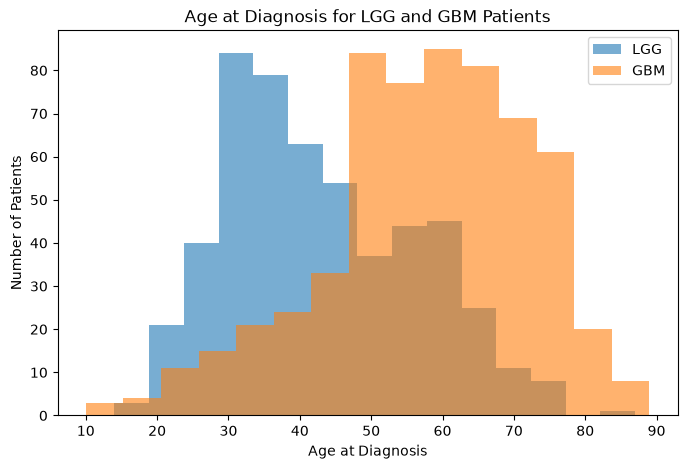

In [22]:
plt.figure(figsize=(8, 5))

for tumor_type in ["LGG", "GBM"]:
    subset = eda[eda["type"] == tumor_type]
    plt.hist(
        subset["age_at_initial_pathologic_diagnosis"],
        bins=15,
        alpha=0.6,
        label=tumor_type
    )

plt.xlabel("Age at Diagnosis")
plt.ylabel("Number of Patients")
plt.title("Age at Diagnosis for LGG and GBM Patients")
plt.legend()
plt.show()

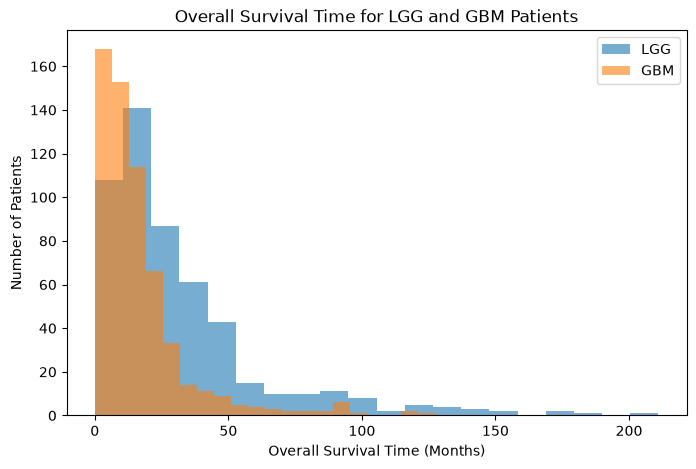

In [23]:
plt.figure(figsize=(8, 5))

for tumor_type in ["LGG", "GBM"]:
    subset = eda[eda["type"] == tumor_type]
    plt.hist(
        subset["OS_months"].dropna(),
        bins=20,
        alpha=0.6,
        label=tumor_type
    )

plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Number of Patients")
plt.title("Overall Survival Time for LGG and GBM Patients")
plt.legend()
plt.show()

<Figure size 700x500 with 0 Axes>

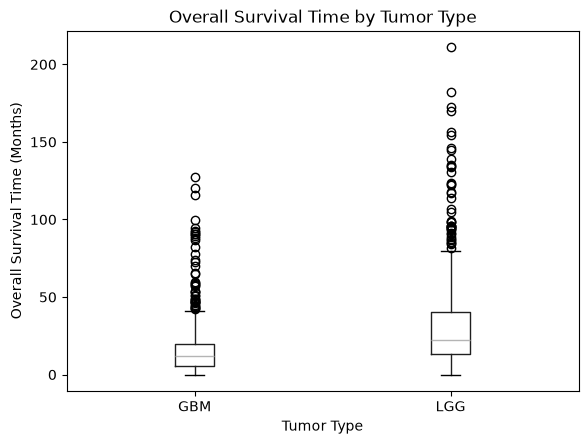

In [24]:
plt.figure(figsize=(7, 5))

eda.boxplot(
    column="OS_months",
    by="type",
    grid=False
)

plt.xlabel("Tumor Type")
plt.ylabel("Overall Survival Time (Months)")
plt.title("Overall Survival Time by Tumor Type")
plt.suptitle("")
plt.show()

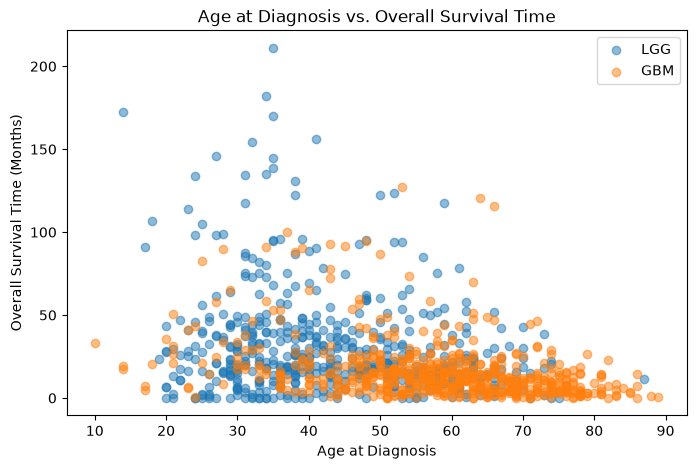

In [25]:
plt.figure(figsize=(8, 5))

for tumor_type in ["LGG", "GBM"]:
    subset = eda[eda["type"] == tumor_type]
    
    plt.scatter(
        subset["age_at_initial_pathologic_diagnosis"],
        subset["OS_months"],
        alpha=0.5,
        label=tumor_type
    )

plt.xlabel("Age at Diagnosis")
plt.ylabel("Overall Survival Time (Months)")
plt.title("Age at Diagnosis vs. Overall Survival Time")
plt.legend()
plt.show()

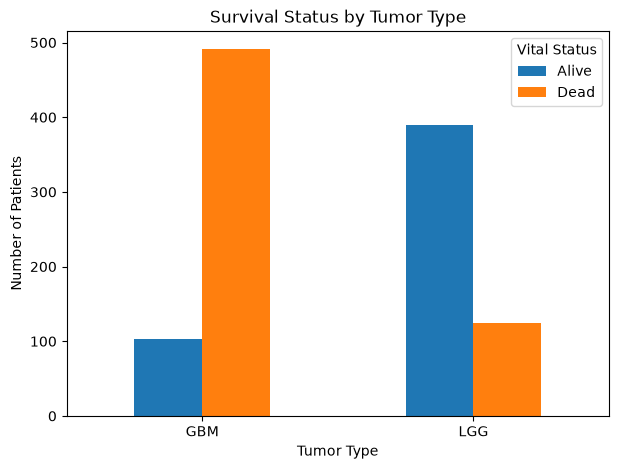

In [26]:
survival_counts = pd.crosstab(eda["type"], eda["vital_status"])

survival_counts.plot(kind="bar", figsize=(7, 5))

plt.xlabel("Tumor Type")
plt.ylabel("Number of Patients")
plt.title("Survival Status by Tumor Type")
plt.xticks(rotation=0)
plt.legend(title="Vital Status")
plt.show()

In [27]:
survival_percent = pd.crosstab(
    eda["type"],
    eda["vital_status"],
    normalize="index"
) * 100

survival_percent.round(1)

vital_status,Alive,Dead
type,,
GBM,17.3,82.7
LGG,75.7,24.3


In [28]:
missing_summary = pd.DataFrame({
    "Missing Count": eda.isna().sum(),
    "Missing Percent": (eda.isna().mean() * 100).round(1)
})

missing_summary

,Missing Count,Missing Percent
bcr_patient_barcode,0,0.0
type,0,0.0
age_at_initial_pathologic_diagnosis,0,0.0
gender,0,0.0
race,35,3.2
histological_type,0,0.0
histological_grade,597,53.7
vital_status,2,0.2
tumor_status,89,8.0
OS,0,0.0


In [29]:
correlation = eda[[
    "age_at_initial_pathologic_diagnosis",
    "OS_months"
]].corr()

correlation.round(3)

,age_at_initial_pathologic_diagnosis,OS_months
age_at_initial_pathologic_diagnosis,1.000,-0.343
OS_months,-0.343,1.000


In [30]:
eda.groupby("type").apply(
    lambda x: x["age_at_initial_pathologic_diagnosis"].corr(x["OS_months"])
)

type
GBM   -0.343431
LGG   -0.196313
dtype: float64

In [31]:
Q1 = eda["OS_months"].quantile(0.25)
Q3 = eda["OS_months"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

survival_outliers = eda[
    (eda["OS_months"] < lower_bound) |
    (eda["OS_months"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Number of potential outliers:", len(survival_outliers))

Lower bound: -23.98
Upper bound: 59.96
Number of potential outliers: 84


In [32]:
Q1_age = eda["age_at_initial_pathologic_diagnosis"].quantile(0.25)
Q3_age = eda["age_at_initial_pathologic_diagnosis"].quantile(0.75)
IQR_age = Q3_age - Q1_age

lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age

age_outliers = eda[
    (eda["age_at_initial_pathologic_diagnosis"] < lower_age) |
    (eda["age_at_initial_pathologic_diagnosis"] > upper_age)
]

print("Lower bound:", round(lower_age, 2))
print("Upper bound:", round(upper_age, 2))
print("Number of potential age outliers:", len(age_outliers))

Lower bound: 0.5
Upper bound: 100.5
Number of potential age outliers: 0


In [33]:
eda.to_csv("glioma_cleaned_eda.csv", index=False)

In [34]:
print("Final dataset shape:", eda.shape)
print("Duplicate rows:", eda.duplicated().sum())
print("LGG patients:", (eda["type"] == "LGG").sum())
print("GBM patients:", (eda["type"] == "GBM").sum())

Final dataset shape: (1111, 12)
Duplicate rows: 0
LGG patients: 515
GBM patients: 596
